# Cleaning Data
#### วิธีทำ
1. Load data
2. แปลงโครงสร้างตาราง
3. แปลงราคาเป็นผลตอบแทน
4. จัดการค่าว่าง
5. ปรับเสกล

In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler


# step 1 
df = pd.read_csv('NASDAQ-100/NASDAQ_100_Data_From_2010.csv', sep='\t')
df['Date'] = pd.to_datetime(df['Date'])

# step 2
features = ['Open','High', 'Low', 'Close', 'Adj Close', 'Volume']
multi_matrix = df.pivot(index='Date', columns='Name', values=features)
multi_matrix.columns.names = ['Feature', 'Name'] #ตั้งชื่อชั้นคอลัมน์ไว้ใช้ตอนสลับมิติ

# step 3
multi_matrix = multi_matrix.replace(0, np.nan)
returns_matrix = np.log(multi_matrix / multi_matrix.shift(1)).iloc[1:]

# step 4
has_null = returns_matrix.isnull().any().groupby(level='Name').any()
clean_returns = returns_matrix.loc[:, returns_matrix.columns.get_level_values('Name').isin(has_null[~has_null].index)]

# step 5
scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(clean_returns),
                        index=clean_returns.index, columns=clean_returns.columns)

X_df = scaled_df.T.unstack(level='Feature')
X = X_df.values
stock_names = X_df.index.tolist()

print(stock_names)
print(X.shape)

['AAPL', 'ADBE', 'ADI', 'ADP', 'ADSK', 'AEP', 'ALGN', 'AMAT', 'AMGN', 'AMZN', 'ANSS', 'ASML', 'ATVI', 'AVGO', 'BIDU', 'BIIB', 'BKNG', 'CDNS', 'CERN', 'CHKP', 'CMCSA', 'COST', 'CPRT', 'CSCO', 'CSX', 'CTAS', 'CTSH', 'DLTR', 'EA', 'EBAY', 'EXC', 'FAST', 'FISV', 'GILD', 'GOOG', 'GOOGL', 'HON', 'IDXX', 'ILMN', 'INCY', 'INTC', 'INTU', 'ISRG', 'KDP', 'KLAC', 'LRCX', 'LULU', 'MAR', 'MCHP', 'MDLZ', 'MELI', 'MNST', 'MRVL', 'MSFT', 'MTCH', 'MU', 'NFLX', 'NTES', 'NVDA', 'ORLY', 'PAYX', 'PCAR', 'PEP', 'QCOM', 'REGN', 'ROST', 'SBUX', 'SIRI', 'SNPS', 'SWKS', 'TCOM', 'TMUS', 'TXN', 'VRSK', 'VRSN', 'WBA', 'XLNX']
(77, 17652)


## GMM ร่วมกับการใช้ข้อมูลธรรมดา

In [14]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=5, covariance_type='spherical', 
                      n_init=5, random_state=42).fit(X)

labels = gmm.predict(X)

## ใช้ T-SNE ลดมิติเพื่อดูการเกาะกลุ่มของข้อมูล GMM แบบ Raw Data

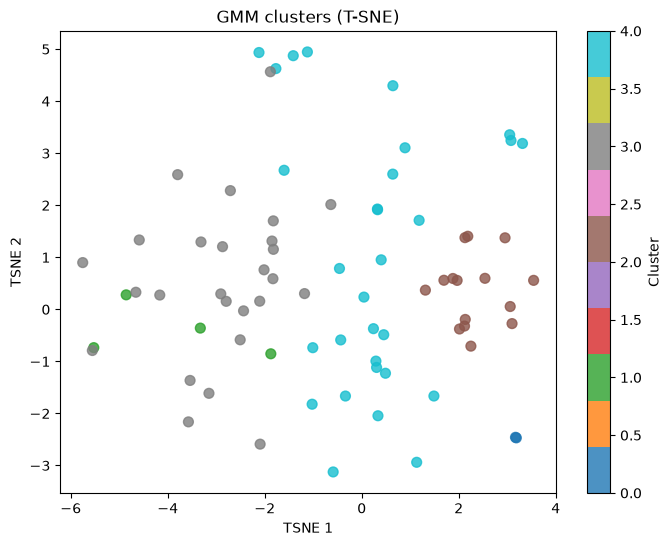

In [22]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, cmap='tab10', s=50, alpha=0.8)
plt.xlabel('TSNE 1')
plt.ylabel('TSNE 2')
plt.title('GMM clusters (T-SNE)')
plt.colorbar(sc, label='Cluster')
plt.show()

## GMM ร่วมกับการใช้ข้อมูลธรรมดา ที่ผ่านการทำ PCA

[0.05688002 0.1004427  0.13237715 0.16242724 0.18838368 0.21209212
 0.23351968 0.25375064 0.27201145 0.28970734 0.30692671 0.32349548
 0.33986172 0.35607316 0.37198716 0.38748819 0.40289679 0.41799862
 0.43282418 0.44743983 0.46178248 0.47579659 0.48968927 0.50326471
 0.51676564 0.53009457 0.54330776 0.55619333 0.56898027 0.58163907
 0.5940801  0.60637505 0.61839502 0.63030948 0.64209216 0.65377194
 0.6653095  0.67674953 0.68802394 0.69921004 0.71025368 0.72112733
 0.73195093 0.74263046 0.75315085 0.76351717 0.77369196 0.78376926
 0.79378419 0.80378177]


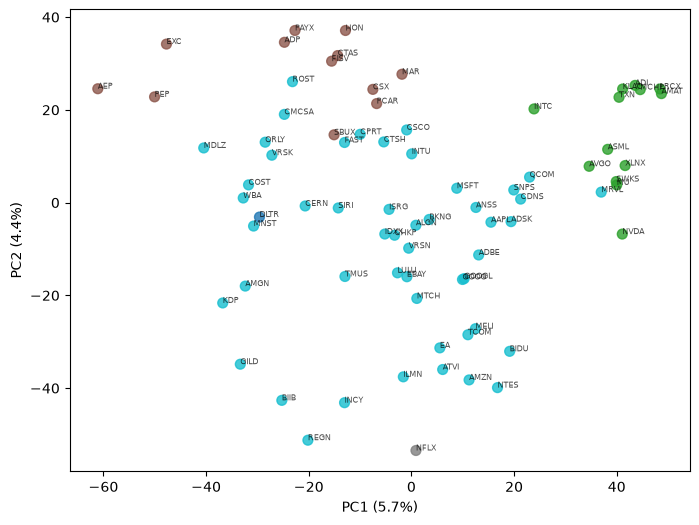

In [40]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.8, random_state=42)
X_pca = pca.fit_transform(X)

gmm = GaussianMixture(n_components=5, covariance_type='spherical', 
                      n_init=10, random_state=42).fit(X_pca)
labels = gmm.predict(X_pca)

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=50, alpha=0.8)

for i, name in enumerate(stock_names):
    plt.annotate(name, (X_pca[i, 0], X_pca[i, 1]), fontsize=6, alpha=0.7)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.show()

## สรุปชื่อหุ้นและนับจำนวนต่อ cluster

In [48]:
result = pd.DataFrame({'Name': stock_names, 'Cluster': labels})
print(np.bincount(labels))     # ต้องตรงกับ Count ในตารางสรุป

summary = (result.groupby('Cluster')['Name']
                 .agg(Count='count', Stocks=lambda s: ', '.join(s))
                 .reset_index())
print(summary)

[ 1 13 12  1 50]
   Cluster  Count  \
0        0      1   
1        1     13   
2        2     12   
3        3      1   
4        4     50   

                                                                                                                                                                                                                                                                                                     Stocks  
0                                                                                                                                                                                                                                                                                                      DLTR  
1                                                                                                                                                                                                                                  ADI, AMAT, ASML, AVGO, IN